# Part 1 — final anchored/Cand2 model

**Selected submission: .89935 user-reported Kaggle sample-wise F1.** This notebook explains and reconstructs the exact 80% anchored / 20% strict-inductive, five-seed Cand2 model.

Run All recomputes retained validation scores and the exact final CSV, then **freshly fits both components from the supplied data**, including all five Cand2 seeds, for validation and final235. Stored scores enter only the post-fit checks. Set `RUN_FRESH_TRAINING=False` for a quicker retained-evidence review; prior fresh-fit receipts are also included.

Read in order: data → anchored pseudo-labeling → Cand2 → fixed blend → evaluation → exact export → fresh training. This notebook replaces the older anchored-only entry point; it does not change the frozen recipe.
Run with Python 3.12 and the pinned `requirements.txt` beside this notebook. In Colab, extract the complete ZIP, change into `midterm/part1`, and install those dependencies before running. The supplied inputs and selected evidence are included; no Git checkout, private path, external trial data, or model cache is required. Notebook 05 contains the complete packaged Python source.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

# Works from the extracted part1 directory or from the repository root.
options = [Path.cwd(), Path.cwd() / "submission/midterm/part1", Path.cwd() / "midterm/part1"]
HOME = next((p for p in options if (p / "resources/handin.py").is_file()), None)
if HOME is None:
    raise RuntimeError("Extract the complete Part 1 ZIP and open this notebook beside its resources folder.")
RES = HOME / "resources"
OUT = HOME / "generated"
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(RES))
import handin as h
P1, LABELS, EMB = h.P1, h.LABELS, h.EMB
# Stable numerical behavior; release automatically when the kernel exits.
thread_limit = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
display(h.verify_resources())

{'files': 763, 'hashes_match': True, 'external_checkout_required': False}

## Data and fitting boundaries

The original training data has 157 complete gold label rows and 1,014 rows with all five labels masked as −100. The separate validation set has 78 gold rows. The final submission uses 235 gold rows plus the original masked rows. Test has 312 rows and enters prediction only. IDs align records; year is used for chronological checks, not as a feature. Supplied labels are preserved.

In [2]:
train, val, test = h.data()
known = train[LABELS].ge(0).all(axis=1)
assert known.sum() == 157 and (~known).sum() == 1014 and len(val) == 78 and len(test) == 312
assert train.loc[~known, LABELS].eq(-100).all().all()
display(pd.DataFrame({"rows": [len(train), len(val), len(test)], "supplied labels": [157,78,0]}, index=["training","validation","test"]))
label_rates = pd.DataFrame({"training gold": train.loc[known,LABELS].mean(), "validation": val[LABELS].mean()})
display(label_rates)

,rows,supplied labels
training,1171,157
validation,78,78
test,312,0


,training gold,validation
Safety,0.101911,0.115385
Funding,0.050955,0.051282
Efficacy,0.108280,0.179487
Recruitment,0.643312,0.641026
Other,0.159236,0.128205


## Anchored: clustering-assisted self-training

1. Standardize all permitted fitting embeddings. Fit 30-dimensional PCA and a 30-component diagonal GMM, three restarts, seed zero. Query inputs never fit these transformations.
2. Combine multiclass logistic regression (`C=.1`), cosine 10-neighbor voting and shrinkage LDA with weights **.5/.3/.2**. Classifiers use all 150 coordinates. Positive labels are expanded into multiclass examples; logistic weights normalize each gold row and remain anchored to gold class weights. Neighbor votes retain every positive label.
3. Build a teacher from **95% classifier scores + 5% GMM label profiles**. Accept masked rows with maximum score ≥.8; select labels at .3 plus argmax. Two refreshes give three classifier fits. Only logistic pseudo-rows receive weight .25; LDA and neighbor votes use their original weighting.

The final anchored fit accepted 757 masked rows. These are generated labels, not verified answers. The exact implementation is included in `resources/part1/anchored_solution.py` and notebook 05.

## Cand2: a distinct graph/feature component

Cand2 models eight label combinations and converts their probabilities into five label marginals. It adds soft k-means-8 memberships and 20-neighbor label-vote features. A Correct-and-Smooth labeler uses a symmetric 10-neighbor graph on standardized, PCA-64, L2-normalized embeddings. Its generated-label weight is .0630724910, confidence cutoff .5, correction coefficient .8 and smoothing coefficient .419961977. Classification uses balanced weighted shrinkage LDA.

Five seeds (0–4) are averaged. Temperature fitting and label-derived features use inner grouped refits and masked-duplicate purges. The original supplied manifest's transductive flag is provenance; the strict adapter overrides fitting access. Standalone Cand2 used expected-F1 decoding and scored .89102. The winner consumes its marginals instead.

The implementation follows the supplied Dylan pipeline, with the separately documented strict adapter. Correct-and-Smooth: Huang et al., [arXiv:2010.13993](https://arxiv.org/abs/2010.13993). Source provenance is retained with the frozen studies.

In [3]:
manifest = json.loads((P1 / "experiments/cand2_submission_v1/original_manifest.json").read_text())
display(manifest["config"]["model"])
print("Actual execution: strict-inductive adapter; seeds 0–4; test inputs prediction only.")

{'features': {'scale': True, 'pca': None, 'l2': False, 'blocks': {}},
 'synth': [{'type': 'kmeans', 'k': 8, 'out': 'soft'},
  {'type': 'knn_vote', 'k': 20}],
 'labeler': {'type': 'cs',
  'graph': {'space': {'scale': True, 'pca': 64, 'l2': True},
   'k': 10,
   's': 1.0,
   'sym': 'max'},
  'lam': 0.06307249103049938,
  'a1': 0.8,
  'a2': 0.4199619766036297,
  'hard': True,
  'tau': 0.5},
 'clf': {'type': 'lda', 'class_weight': 'balanced'},
 'temperature': True}

Actual execution: strict-inductive adapter; seeds 0–4; test inputs prediction only.


## Fixed decision rule and original validation

`score = .8 * anchored_score + .2 * Cand2_label_marginal`.

Select every label scoring at least .3 and always include argmax. These are selection scores, not established calibrated probabilities. This is arithmetic pooling, with no learned final combiner. The validation below belongs to a separate 157-label fit; it is not independent validation of the final 235-label artifact.

sample_f1    0.891026
macro_f1     0.765430
dtype: float64

,label,precision,recall,f1,support
0,Safety,1.000000,0.888889,0.941176,9
1,Funding,1.000000,0.500000,0.666667,4
2,Efficacy,0.733333,0.785714,0.758621,14
3,Recruitment,0.980392,1.000000,0.990099,50
4,Other,0.571429,0.400000,0.470588,10


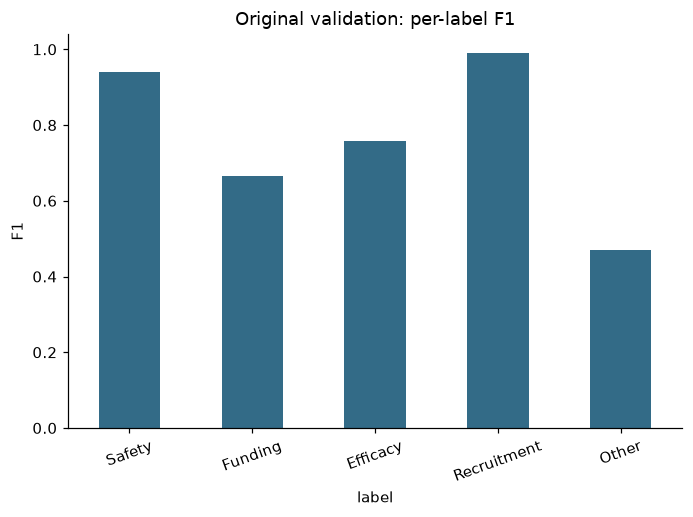

In [4]:
validation = h.arrays(P1 / "experiments/cand2_followup_v1/inputs/strict_inductive__validation.npz")
np.testing.assert_array_equal(validation["ids"], val.ID.to_numpy(str))
np.testing.assert_array_equal(validation["truth"], val[LABELS].to_numpy())
scores = .8 * validation["anchored_scores"] + .2 * validation["cand2_scores"]
prediction = h.select_reasons(scores)
headline, labels = h.metrics(validation["truth"], prediction)
assert abs(headline["sample_f1"] - .8910256410256411) < 1e-12
assert np.array_equal(prediction, validation["anchored_predictions"])
display(pd.Series(headline), labels)
labels.to_csv(OUT / "validation_per_label.csv", index=False)
ax = labels.set_index("label").f1.plot.bar(color="#336b87", ylim=(0,1.04), rot=20, title="Original validation: per-label F1")
ax.set_ylabel("F1"); plt.tight_layout(); plt.savefig(OUT / "validation_per_label.png"); plt.show()

## Reconstruct the exact scored CSV

No hidden-test labels are used. Hash equality identifies the intended exact file; the .89935 score was reported by the user, not queried from Kaggle. Outputs go to `generated/`, so the immutable scored copy is preserved.

In [5]:
final = h.arrays(P1 / "experiments/cand2_followup_v1/blend_final_predictions.npz")
np.testing.assert_array_equal(final["ids"], test.ID.to_numpy(str))
final_scores = .8 * final["anchored_scores"] + .2 * final["cand2_scores"]
np.testing.assert_allclose(final_scores, final["scores"], atol=1e-12, rtol=0)
final_prediction = h.select_reasons(final_scores)
np.testing.assert_array_equal(final_prediction, final["predictions"])
submission = h.frame(final["ids"], final_prediction)
submission.to_csv(OUT / "reconstructed_submission.csv", index=False, lineterminator="\n")
assert h.sha(OUT / "reconstructed_submission.csv") == h.WINNER_SHA
assert h.sha(HOME / "part1_best_submission.csv") == h.WINNER_SHA
print("312 rows; exact winner SHA-256:", h.WINNER_SHA)
display(submission.head())

312 rows; exact winner SHA-256: c20aa937fa8b1e5aea55bcd6564c6acd952f0d74030cc7c1a437eac54a1ee257


,ID,Predicted
0,TR00756,Efficacy
1,TR05267,Safety
2,TR10354,Safety
3,TR01930,Recruitment
4,TR01046,Other


## Fresh fitting from the supplied data

The switch below defaults to `True`: fit anchored and all five Cand2 seeds for both original validation and final235. Stored scores are used **only after fitting for verification**. The final CSV must reproduce the immutable winner hash. The generated label export keeps supplied labels, identifies accepted anchored pseudo-labels, and leaves unaccepted rows masked. Runtime depends on hardware; the included receipts record the preparation machine's actual timings.

Disabling the switch skips fitting and only displays the earlier preparation receipts. With the default enabled, the outputs below document fresh fits performed by this notebook execution.

In [6]:
RUN_FRESH_TRAINING = True
if RUN_FRESH_TRAINING:
    validation_receipt, _ = h.fit_winner(validation=True, output=OUT / "fresh_validation")
    final_receipt, _ = h.fit_winner(validation=False, output=OUT / "fresh_final")
    display(validation_receipt, final_receipt)
else:
    for name in ["fresh_validation.json", "fresh_final.json"]:
        path = HOME / "results" / name
        if path.exists():
            display(json.loads(path.read_text()))
    print("Fresh training is disabled in this execution. Enable the switch to reproduce it.")

Validation seed 0 complete


Validation seed 1 complete


Validation seed 2 complete


Validation seed 3 complete


Validation seed 4 complete


Final235 seed 0 complete


... (2 outputs left out)

Final235 seed 3 complete


Final235 seed 4 complete


{'validation': True,
 'gold': 157,
 'originally_masked': 1014,
 'rows': 78,
 'seeds': [0, 1, 2, 3, 4],
 'fresh_anchored': True,
 'fresh_cand2': True,
 'test_inputs_in_fit': False,
 'max_anchored_error': 0.0,
 'max_cand2_error': 0.0,
 'identical_predictions': True,
 'seconds': 12.9588777506724,
 'anchored_refreshes': [{'step': 0,
   'known': 157,
   'generated': 0,
   'known_weight': 157.0,
   'generated_weight': 0.0},
  {'step': 1,
   'known': 157,
   'generated': 657,
   'known_weight': 157.0,
   'generated_weight': 96.48171234402852},
  {'step': 2,
   'known': 157,
   'generated': 758,
   'known_weight': 157.0,
   'generated_weight': 116.410619986631}]}

{'validation': False,
 'gold': 235,
 'originally_masked': 1014,
 'rows': 312,
 'seeds': [0, 1, 2, 3, 4],
 'fresh_anchored': True,
 'fresh_cand2': True,
 'test_inputs_in_fit': False,
 'max_anchored_error': 0.0,
 'max_cand2_error': 0.0,
 'identical_predictions': True,
 'seconds': 19.31538845784962,
 'anchored_refreshes': [{'step': 0,
   'known': 235,
   'generated': 0,
   'known_weight': 235.0,
   'generated_weight': 0.0},
  {'step': 1,
   'known': 235,
   'generated': 685,
   'known_weight': 235.0,
   'generated_weight': 102.79687754649603},
  {'step': 2,
   'known': 235,
   'generated': 757,
   'known_weight': 235.0,
   'generated_weight': 119.52692709831274}],
 'submission_sha256': 'c20aa937fa8b1e5aea55bcd6564c6acd952f0d74030cc7c1a437eac54a1ee257'}

## Interpretation

The final blend's .89935 improves the reported score by .00299 over anchored and .00085 over the earlier anchored/LDA blend. It does not win every local comparison: the earlier LDA blend has higher Pooled235 mean. Our winner also missed the original requirement of five repeat wins in both pools. Its exploratory manual submission determined the final report choice. Notebook 03 reconstructs that evidence and preserves the selection limitation. Funding and Other have only four and ten validation positives; their metrics are particularly uncertain.